**Install libraries**

In [1]:
!pip install torch matplotlib numpy

**Import libraries**

In [2]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


**Set device and parameters**

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

alpha = 0.1

x_min = 0.0
x_max = 1.0

t_min = 0.0
t_max = 1.0

Using device: cpu


**Create the PINN neural network**

In [4]:
class PINN(nn.Module):

    def __init__(self):
        super(PINN, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 32),
            nn.Tanh(),

            nn.Linear(32, 32),
            nn.Tanh(),

            nn.Linear(32, 32),
            nn.Tanh(),

            nn.Linear(32, 1)
        )

    def forward(self, x, t):

        inputs = torch.cat((x, t), dim=1)

        return self.network(inputs)

**Create the model**

In [5]:
model = PINN().to(device)

print(model)

PINN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): Tanh()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


**Generate training points**

In [6]:
N_f = 5000

x_f = torch.rand(N_f, 1) * (x_max - x_min) + x_min
t_f = torch.rand(N_f, 1) * (t_max - t_min) + t_min

x_f = x_f.to(device)
t_f = t_f.to(device)

x_f.requires_grad = True
t_f.requires_grad = True

print("Physics points:", N_f)

Physics points: 5000


**Initial condition points**

In [7]:
N_initial = 500

x_initial = torch.rand(N_initial, 1)
t_initial = torch.zeros(N_initial, 1)

u_initial = torch.sin(torch.pi * x_initial)

x_initial = x_initial.to(device)
t_initial = t_initial.to(device)
u_initial = u_initial.to(device)

print("Initial condition points:", N_initial)

Initial condition points: 500


**Boundary condition points**

In [8]:
N_boundary = 500

t_boundary = torch.rand(N_boundary, 1)

x_left = torch.zeros(N_boundary, 1)
x_right = torch.ones(N_boundary, 1)

u_boundary = torch.zeros(N_boundary, 1)

x_left = x_left.to(device)
x_right = x_right.to(device)
t_boundary = t_boundary.to(device)
u_boundary = u_boundary.to(device)

print("Boundary points:", N_boundary)

Boundary points: 500


**Physics loss**

In [9]:
def physics_loss(model, x, t):

    u = model(x, t)

    u_t = torch.autograd.grad(
        u,
        t,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_x = torch.autograd.grad(
        u,
        x,
        grad_outputs=torch.ones_like(u),
        create_graph=True
    )[0]

    u_xx = torch.autograd.grad(
        u_x,
        x,
        grad_outputs=torch.ones_like(u_x),
        create_graph=True
    )[0]

    residual = u_t - alpha * u_xx

    loss = torch.mean(residual ** 2)

    return loss

**Optimizer**

In [10]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Optimizer created!")

Optimizer created!


**Training**

In [11]:
epochs = 5000

loss_history = []

for epoch in range(epochs):

    optimizer.zero_grad()

    # Physics loss
    loss_physics = physics_loss(
        model,
        x_f,
        t_f
    )

    # Initial condition prediction
    u_pred_initial = model(
        x_initial,
        t_initial
    )

    loss_initial = torch.mean(
        (u_pred_initial - u_initial) ** 2
    )

    # Left boundary
    u_pred_left = model(
        x_left,
        t_boundary
    )

    loss_left = torch.mean(
        u_pred_left ** 2
    )

    # Right boundary
    u_pred_right = model(
        x_right,
        t_boundary
    )

    loss_right = torch.mean(
        u_pred_right ** 2
    )

    # Total loss
    loss = (
        loss_physics
        + loss_initial
        + loss_left
        + loss_right
    )

    # Backpropagation
    loss.backward()

    # Update model
    optimizer.step()

    # Store loss
    loss_history.append(loss.item())

    # Print every 500 epochs
    if epoch % 500 == 0:
        print(
            f"Epoch {epoch}: "
            f"Loss = {loss.item():.6f}"
        )

Epoch 0: Loss = 0.733326
Epoch 500: Loss = 0.000870
Epoch 1000: Loss = 0.000155
Epoch 1500: Loss = 0.000101
Epoch 2000: Loss = 0.000078
Epoch 2500: Loss = 0.000062
Epoch 3000: Loss = 0.000062
Epoch 3500: Loss = 0.000042
Epoch 4000: Loss = 0.000035
Epoch 4500: Loss = 0.000029


**Plot training loss**

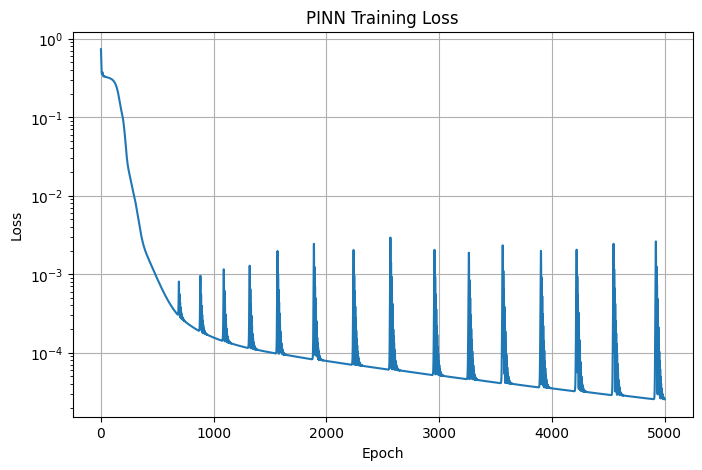

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.yscale("log")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title("PINN Training Loss")

plt.grid()

plt.show()

**Predict temperature**

In [13]:
x_test = torch.linspace(
    0,
    1,
    100
)

t_test = torch.linspace(
    0,
    1,
    100
)

X, T = torch.meshgrid(
    x_test,
    t_test,
    indexing="ij"
)

X_flat = X.reshape(-1, 1).to(device)
T_flat = T.reshape(-1, 1).to(device)

with torch.no_grad():

    U_pred = model(
        X_flat,
        T_flat
    )

U_pred = U_pred.cpu().numpy()

U_pred = U_pred.reshape(
    100,
    100
)

print("Prediction completed!")

Prediction completed!


**Temperature heatmap**

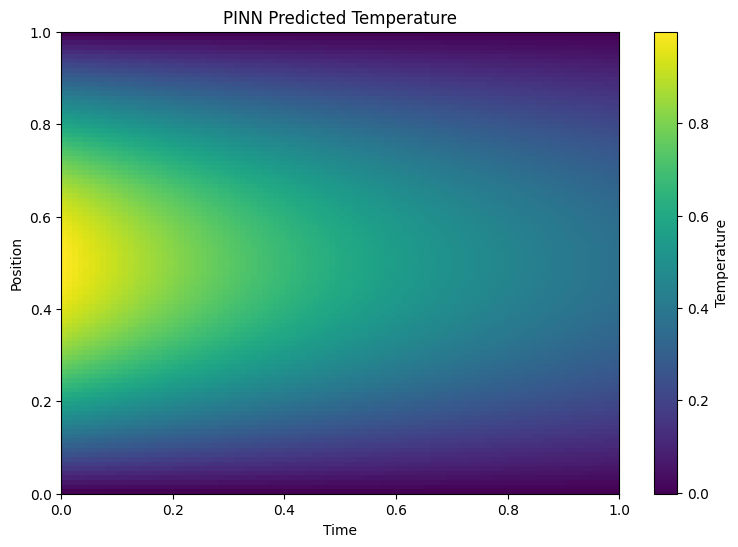

In [14]:
plt.figure(figsize=(9, 6))

plt.imshow(
    U_pred,
    extent=[0, 1, 0, 1],
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Temperature")

plt.xlabel("Time")
plt.ylabel("Position")

plt.title("PINN Predicted Temperature")

plt.show()

**Compare with analytical solution**

In [15]:
U_exact = (
    np.exp(
        -alpha * np.pi**2 * T.numpy()
    )
    * np.sin(
        np.pi * X.numpy()
    )
)

print("Exact solution calculated!")

Exact solution calculated!


**Compare PINN and exact solution**

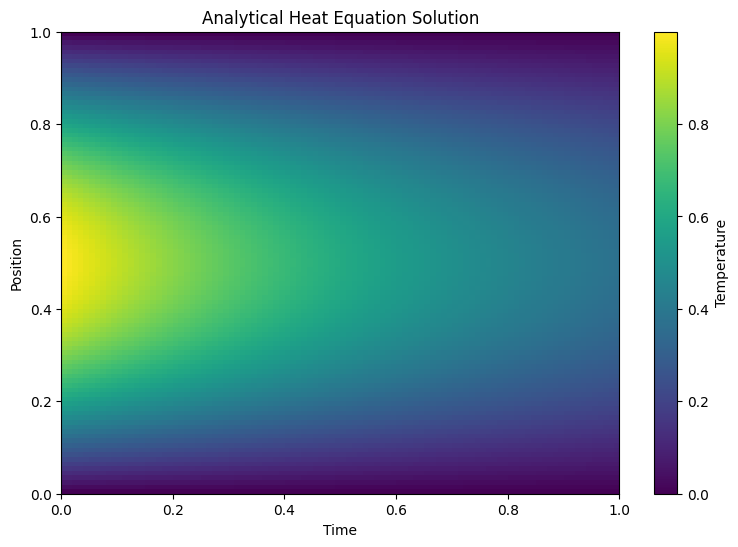

In [16]:
plt.figure(figsize=(9, 6))

plt.imshow(
    U_exact,
    extent=[0, 1, 0, 1],
    origin="lower",
    aspect="auto"
)

plt.colorbar(label="Temperature")

plt.xlabel("Time")
plt.ylabel("Position")

plt.title("Analytical Heat Equation Solution")

plt.show()

**Calculate error**

In [17]:
mse = np.mean(
    (U_pred - U_exact) ** 2
)

rmse = np.sqrt(mse)

print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)

Mean Squared Error: 2.6980555e-07
Root Mean Squared Error: 0.0005194281


**Compare temperature at one time**

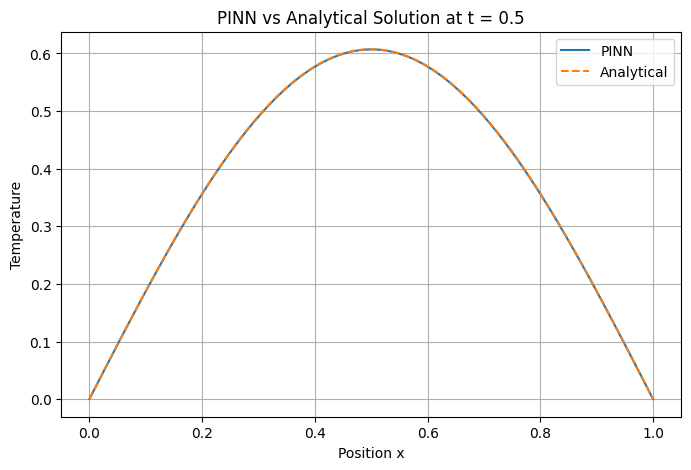

In [18]:
time_index = 50

plt.figure(figsize=(8, 5))

plt.plot(
    x_test.numpy(),
    U_pred[:, time_index],
    label="PINN"
)

plt.plot(
    x_test.numpy(),
    U_exact[:, time_index],
    "--",
    label="Analytical"
)

plt.xlabel("Position x")
plt.ylabel("Temperature")

plt.title("PINN vs Analytical Solution at t = 0.5")

plt.legend()

plt.grid()

plt.show()